# Facial Emotion Recognition — AffectNet Transfer Learning

This notebook trains and compares three transfer learning CNNs (MobileNetV2, DenseNet121, ResNet50) on the AffectNet dataset for 8-class emotion classification. Each model is trained independently with a frozen backbone, fully evaluated, and compared. The best model is then fine-tuned and re-evaluated, and the final model is saved for later webcam inference.

**Classes:** Anger, Contempt, Disgust, Fear, Happy, Neutral, Sad, Surprise

The required libraries are now being imported.

In [1]:
import os, cv2, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
    precision_recall_fscore_support, roc_auc_score, roc_curve, auc)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


GPU availability is now being checked and mixed precision is configured for faster T4 training.

In [2]:
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f"GPU available: {gpus}")
    from tensorflow.keras import mixed_precision
    mixed_precision.set_global_policy("mixed_float16")
    print("Mixed precision policy set to mixed_float16")
else:
    print("No GPU found, running on CPU. Training will be slower.")

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision policy set to mixed_float16


Google Drive is now being mounted and the dataset paths are being defined.

In [3]:
import os
from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

Mounted at /content/drive


## Copying Dataset to Local Storage

The dataset is being copied from Google Drive to Colab's local storage to reduce image loading delays during training.

In [4]:
# ============================================================
# COPY DATASET TO COLAB LOCAL STORAGE
# ============================================================

import os
import shutil

DRIVE_DATASET_ROOT = r"/content/drive/MyDrive/Real_TIme_Emotion_Detection/Dataset"
LOCAL_DATASET_ROOT = "/content/affectnet_dataset"

if not os.path.exists(LOCAL_DATASET_ROOT):
    print("Copying dataset to local storage...")
    shutil.copytree(DRIVE_DATASET_ROOT, LOCAL_DATASET_ROOT)
    print("Dataset copied successfully.")
else:
    print("Local dataset already exists.")

print("Local dataset path:", LOCAL_DATASET_ROOT)

Copying dataset to local storage...
Dataset copied successfully.
Local dataset path: /content/affectnet_dataset


In [5]:
# Define training and test directories
DATASET_ROOT = "/content/affectnet_dataset"

TRAIN_DIR = os.path.join(DATASET_ROOT, "Train")
TEST_DIR = os.path.join(DATASET_ROOT, "Test")

# Explicitly ignore labels.csv
print("Dataset root:", DATASET_ROOT)
print("Training directory:", TRAIN_DIR)
print("Test directory:", TEST_DIR)
print("Training directory exists:", os.path.exists(TRAIN_DIR))
print("Test directory exists:", os.path.exists(TEST_DIR))

Dataset root: /content/affectnet_dataset
Training directory: /content/affectnet_dataset/Train
Test directory: /content/affectnet_dataset/Test
Training directory exists: True
Test directory exists: True


The class names, folder-to-index mapping, and core image configuration are now being set up. The folder names on disk are lowercase, so a mapping is used to keep display names readable while matching the actual directory names.

In [6]:
CLASS_NAMES = ["Anger", "Contempt", "Disgust", "Fear", "Happy", "Neutral", "Sad", "Surprise"]
FOLDER_NAMES = [c.lower() for c in CLASS_NAMES]
FOLDER_TO_IDX = {f: i for i, f in enumerate(FOLDER_NAMES)}
IDX_TO_CLASS = {i: c for i, c in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print("Class mapping (folder name -> index -> display name):")
for f, i in FOLDER_TO_IDX.items():
    print(f"  {f:10s} -> {i} -> {IDX_TO_CLASS[i]}")

Class mapping (folder name -> index -> display name):
  anger      -> 0 -> Anger
  contempt   -> 1 -> Contempt
  disgust    -> 2 -> Disgust
  fear       -> 3 -> Fear
  happy      -> 4 -> Happy
  neutral    -> 5 -> Neutral
  sad        -> 6 -> Sad
  surprise   -> 7 -> Surprise


The dataset is now being scanned. Labels are inferred purely from folder names, and labels.csv is ignored completely.

In [7]:
def scan_dataset(root_dir, folder_to_idx):
    records = []
    for folder in sorted(os.listdir(root_dir)):
        folder_path = os.path.join(root_dir, folder)
        if not os.path.isdir(folder_path):
            continue
        key = folder.lower()
        if key not in folder_to_idx:
            print(f"Warning: unexpected folder '{folder}' skipped")
            continue
        label_idx = folder_to_idx[key]
        for fname in os.listdir(folder_path):
            if fname.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
                records.append({"filepath": os.path.join(folder_path, fname),
                                 "class_name": IDX_TO_CLASS[label_idx], "label": label_idx})
    return pd.DataFrame(records)

train_df_full = scan_dataset(TRAIN_DIR, FOLDER_TO_IDX)
test_df = scan_dataset(TEST_DIR, FOLDER_TO_IDX)
print(f"Total images found in Train folder: {len(train_df_full)}")
print(f"Total images found in Test folder: {len(test_df)}")

Total images found in Train folder: 16108
Total images found in Test folder: 14518


A quick numeric summary of the class distribution is now being printed.

In [8]:
print("Training folder class distribution:")
print(train_df_full["class_name"].value_counts().reindex(CLASS_NAMES))
print("\nTest folder class distribution:")
print(test_df["class_name"].value_counts().reindex(CLASS_NAMES))

Training folder class distribution:
class_name
Anger       1500
Contempt    1559
Disgust     1229
Fear        1512
Happy       2340
Neutral     2758
Sad         3091
Surprise    2119
Name: count, dtype: int64

Test folder class distribution:
class_name
Anger       1718
Contempt    1312
Disgust     1248
Fear        1664
Happy       2704
Neutral     2368
Sad         1584
Surprise    1920
Name: count, dtype: int64


The dataset is now being visualized: class distributions, a train-vs-test comparison, and one sample image per emotion class.

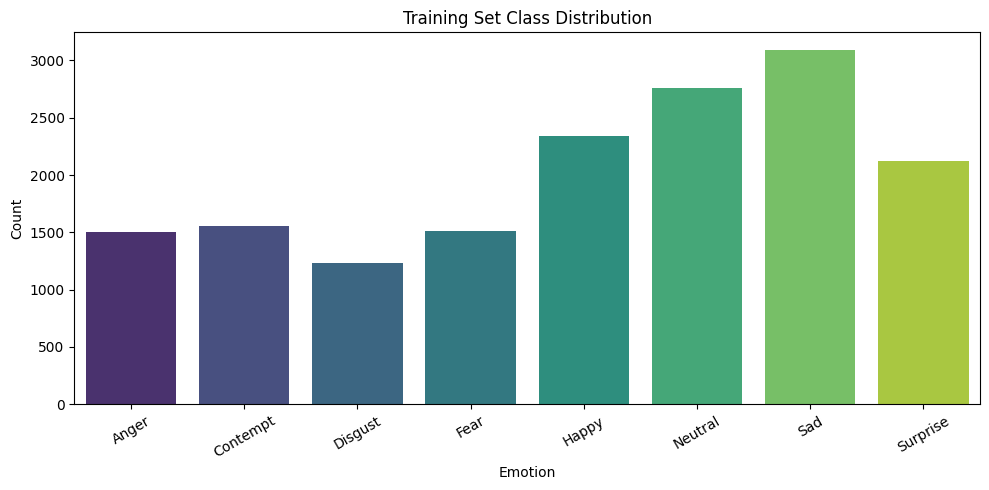

In [9]:
plt.figure(figsize=(10, 5))
sns.countplot(data=train_df_full, x="class_name", order=CLASS_NAMES, palette="viridis")
plt.title("Training Set Class Distribution"); plt.xlabel("Emotion"); plt.ylabel("Count")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

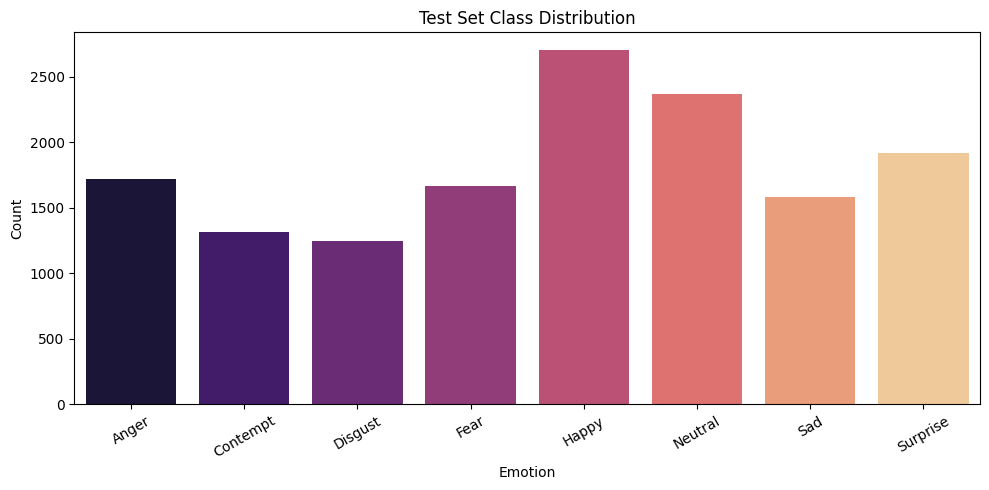

In [10]:
plt.figure(figsize=(10, 5))
sns.countplot(data=test_df, x="class_name", order=CLASS_NAMES, palette="magma")
plt.title("Test Set Class Distribution"); plt.xlabel("Emotion"); plt.ylabel("Count")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

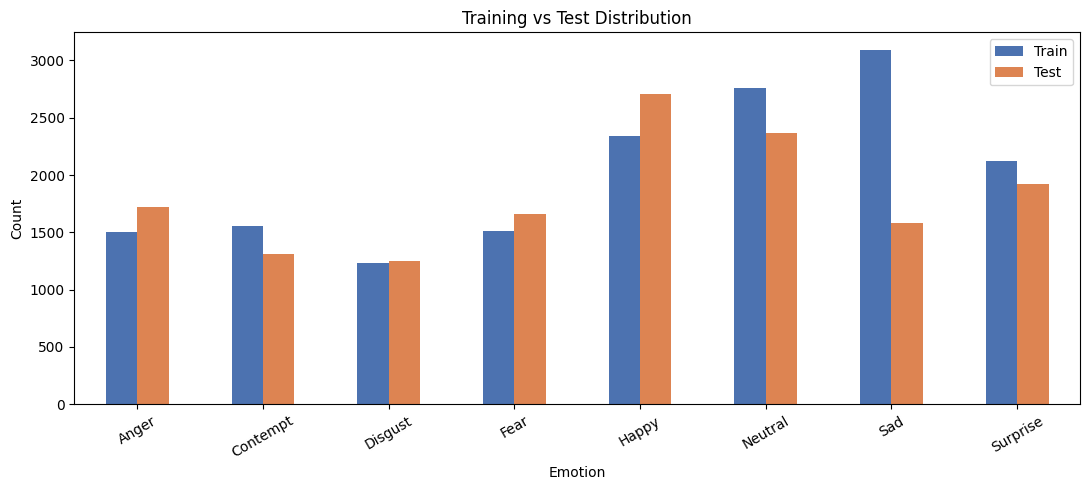

In [11]:
train_counts = train_df_full["class_name"].value_counts().reindex(CLASS_NAMES)
test_counts = test_df["class_name"].value_counts().reindex(CLASS_NAMES)
compare_counts = pd.DataFrame({"Train": train_counts, "Test": test_counts})
compare_counts.plot(kind="bar", figsize=(11, 5), color=["#4C72B0", "#DD8452"])
plt.title("Training vs Test Distribution"); plt.xlabel("Emotion"); plt.ylabel("Count")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

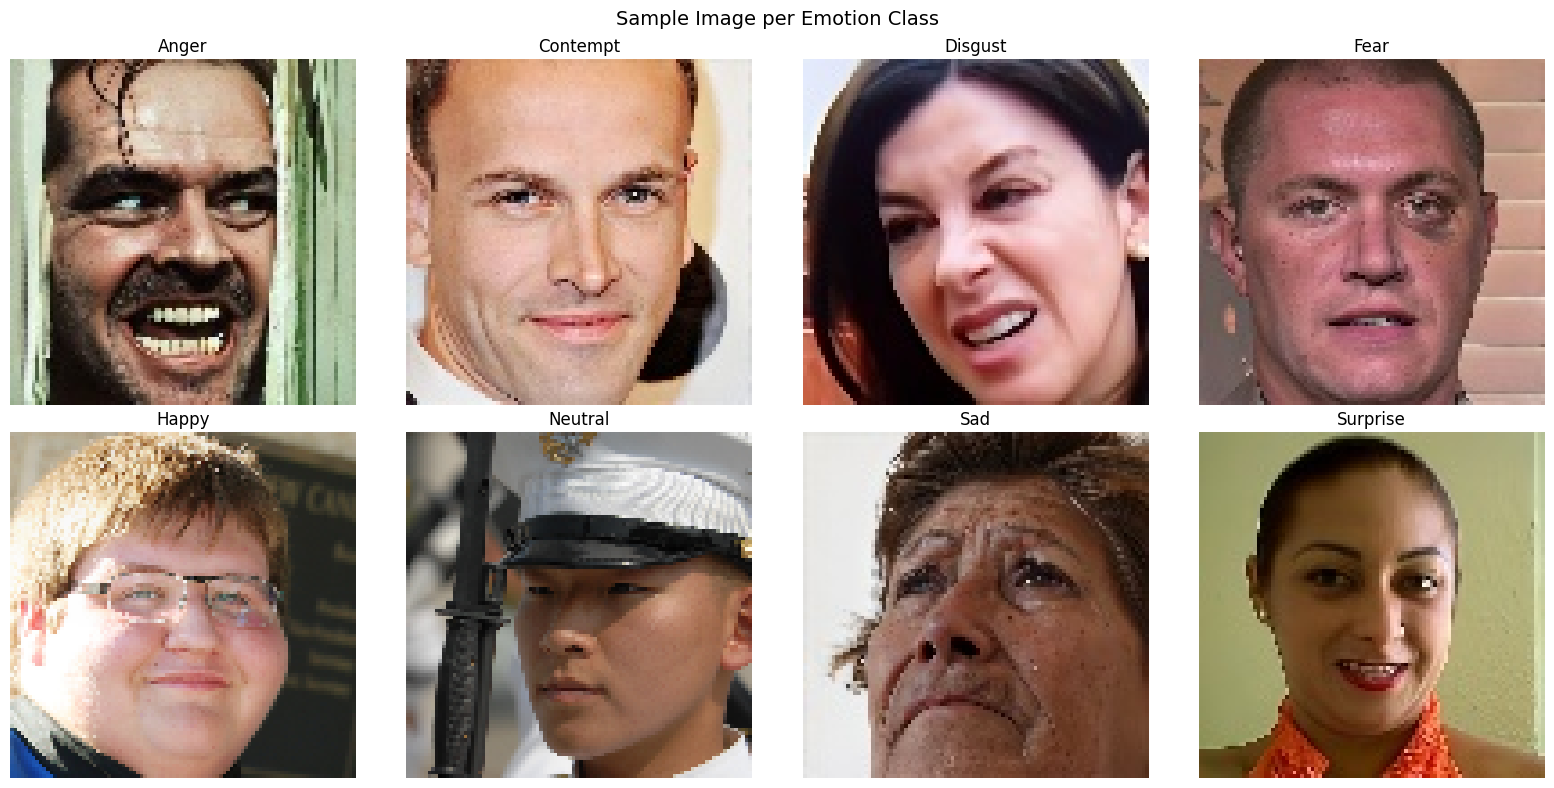

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, cls in zip(axes.flatten(), CLASS_NAMES):
    sample_path = train_df_full[train_df_full["class_name"] == cls].sample(1, random_state=SEED)["filepath"].values[0]
    img = cv2.cvtColor(cv2.imread(sample_path), cv2.COLOR_BGR2RGB)
    ax.imshow(img); ax.set_title(cls); ax.axis("off")
plt.suptitle("Sample Image per Emotion Class", fontsize=14); plt.tight_layout(); plt.show()

A stratified validation split is now being created from the training folder. The Test folder is kept completely separate and is only used for final evaluation.

In [13]:
train_df, val_df = train_test_split(train_df_full, test_size=0.15,
    stratify=train_df_full["label"], random_state=SEED)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print(f"Training images:   {len(train_df)}")
print(f"Validation images: {len(val_df)}")
print(f"Test images:       {len(test_df)}")

Training images:   13691
Validation images: 2417
Test images:       14518


Class weights are now being computed from the actual training labels to handle class imbalance.

In [14]:
class_weights_array = compute_class_weight(class_weight="balanced",
    classes=np.arange(NUM_CLASSES), y=train_df["label"].values)
class_weights = {i: w for i, w in enumerate(class_weights_array)}

print("Calculated class weights:")
for i, w in class_weights.items():
    print(f"  {IDX_TO_CLASS[i]:10s}: {w:.3f}")

Calculated class weights:
  Anger     : 1.342
  Contempt  : 1.292
  Disgust   : 1.638
  Fear      : 1.332
  Happy     : 0.860
  Neutral   : 0.730
  Sad       : 0.651
  Surprise  : 0.950


An efficient tf.data pipeline is now being built to load and resize images as RGB, with prefetching for GPU throughput.

In [17]:
# ============================================================
# IMAGE LOADING FUNCTION
# ============================================================
AUTOTUNE = tf.data.AUTOTUNE
def load_image(filepath, label):
    # Read the image file
    img = tf.io.read_file(filepath)

    # Decode image as RGB
    img = tf.image.decode_image(img, channels=3, expand_animations=False)

    # Resize image to the required model input size
    img = tf.image.resize(img, IMG_SIZE)

    # Set static image shape for TensorFlow
    img.set_shape(IMG_SIZE + (3,))

    # Convert image to float32
    img = tf.cast(img, tf.float32)

    return img, label

# ============================================================
# CREATE TENSORFLOW DATASET
# ============================================================

def make_dataset(df, batch_size=BATCH_SIZE, shuffle=False):
    # Create dataset from image paths and labels
    ds = tf.data.Dataset.from_tensor_slices(
        (df["filepath"].values, df["label"].values)
    )

    # Shuffle training data
    if shuffle:
        ds = ds.shuffle(
            buffer_size=len(df),
            seed=SEED
        )

    # Load images in parallel using AUTOTUNE
    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    # Batch images and prefetch future batches automatically
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)

    return ds

# ============================================================
# CREATE TRAINING, VALIDATION AND TEST DATASETS
# ============================================================

train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("tf.data pipelines ready for train, validation and test sets.")

tf.data pipelines ready for train, validation and test sets.


Only slight, realistic augmentation is used since facial expressions can be distorted by aggressive transforms. This augmentation block is embedded directly inside each model (right after the input layer), so it automatically applies only during training and is a no-op during evaluation and inference.

In [18]:
def build_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
        layers.RandomContrast(0.1),
    ], name="data_augmentation")

Each backbone requires its own `preprocess_input` function. Wrapping a plain Python function in a `Lambda` layer causes a *"Could not locate function 'preprocess_input'"* error when the saved `.keras` model is reloaded later, because Keras cannot serialize an arbitrary function reference. To avoid this, each preprocessing function is wrapped inside a small custom `Layer` subclass registered with `register_keras_serializable`. This keeps preprocessing embedded inside the model (needed for webcam inference) while remaining safely loadable later — as long as these same class definitions are imported/registered before calling `load_model` in the deployment script.

In [19]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

@tf.keras.utils.register_keras_serializable(package="EmotionCNN")
class MobileNetV2Preprocess(layers.Layer):
    def call(self, inputs):
        return mobilenet_preprocess(inputs)

@tf.keras.utils.register_keras_serializable(package="EmotionCNN")
class DenseNet121Preprocess(layers.Layer):
    def call(self, inputs):
        return densenet_preprocess(inputs)

@tf.keras.utils.register_keras_serializable(package="EmotionCNN")
class ResNet50Preprocess(layers.Layer):
    def call(self, inputs):
        return resnet_preprocess(inputs)

PREPROCESS_LAYERS = {
    "MobileNetV2": MobileNetV2Preprocess,
    "DenseNet121": DenseNet121Preprocess,
    "ResNet50": ResNet50Preprocess,
}
print("Preprocessing layers registered:", list(PREPROCESS_LAYERS.keys()))

Preprocessing layers registered: ['MobileNetV2', 'DenseNet121', 'ResNet50']


A reusable model builder is now defined: Input → Augmentation → Model-specific preprocessing → ImageNet backbone (frozen) → GlobalAveragePooling2D → BatchNorm → Dropout → Dense(256) → BatchNorm → Dropout → Softmax(8).

In [20]:
BACKBONE_FNS = {
    "MobileNetV2": tf.keras.applications.MobileNetV2,
    "DenseNet121": tf.keras.applications.DenseNet121,
    "ResNet50": tf.keras.applications.ResNet50,
}

def build_model(name, input_shape=(224, 224, 3), num_classes=NUM_CLASSES):
    inputs = keras.Input(shape=input_shape, name="input_image")
    x = build_augmentation()(inputs)
    x = PREPROCESS_LAYERS[name]()(x)
    backbone = BACKBONE_FNS[name](include_top=False, weights="imagenet", input_shape=input_shape)
    backbone.trainable = False
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.35)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.30)(x)
    outputs = layers.Dense(num_classes, activation="softmax", dtype="float32", name="predictions")(x)
    model = keras.Model(inputs, outputs, name=name)
    return model, backbone

Shared helper functions for callbacks, history plots, predictions, confusion matrices, ROC curves and the full evaluation routine are now defined. These are reused identically for every model to keep the evaluation consistent.

In [21]:

def get_callbacks(checkpoint_path, patience=5):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1),
        keras.callbacks.ModelCheckpoint(checkpoint_path, monitor="val_loss", save_best_only=True),
    ]

def plot_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history.history["accuracy"], label="Train Accuracy")
    axes[0].plot(history.history["val_accuracy"], label="Val Accuracy")
    axes[0].set_title(f"{model_name}: Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend()
    axes[1].plot(history.history["loss"], label="Train Loss")
    axes[1].plot(history.history["val_loss"], label="Val Loss")
    axes[1].set_title(f"{model_name}: Loss"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend()
    plt.tight_layout(); plt.show()

In [22]:
def get_predictions(model, dataset):
    y_true, y_prob = [], []
    for images, labels_batch in dataset:
        y_prob.append(model.predict(images, verbose=0))
        y_true.append(labels_batch.numpy())
    return np.concatenate(y_true), np.concatenate(y_prob)

def plot_confusion(y_true, y_pred, model_name, normalize=False):
    cm = confusion_matrix(y_true, y_pred)
    if normalize:
        cm = cm.astype("float") / cm.sum(axis=1, keepdims=True)
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt=".2f" if normalize else "d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f"{model_name} Confusion Matrix" + (" (Normalized)" if normalize else ""))
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.tight_layout(); plt.show()

def plot_roc_curves(y_true, y_prob, model_name):
    y_true_bin = label_binarize(y_true, classes=np.arange(NUM_CLASSES))
    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(NUM_CLASSES):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
    macro_auc = roc_auc_score(y_true_bin, y_prob, average="macro", multi_class="ovr")
    plt.figure(figsize=(9, 7))
    for i in range(NUM_CLASSES):
        plt.plot(fpr[i], tpr[i], label=f"{CLASS_NAMES[i]} (AUC={roc_auc[i]:.3f})")
    plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
    plt.title(f"{model_name} ROC Curves (Macro AUC={macro_auc:.3f})")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.legend(fontsize=8); plt.tight_layout(); plt.show()
    return roc_auc, macro_auc

In [23]:
results = {}

def evaluate_full(model, model_name, test_dataset, results_store):
    test_loss, test_acc = model.evaluate(test_dataset, verbose=0)
    y_true, y_prob = get_predictions(model, test_dataset)
    y_pred = np.argmax(y_prob, axis=1)
    print(f"\n{model_name} | Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f}")
    print(f"\n{model_name} Classification Report:\n")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))
    plot_confusion(y_true, y_pred, model_name)
    plot_confusion(y_true, y_pred, model_name, normalize=True)
    per_class_auc, macro_auc = plot_roc_curves(y_true, y_prob, model_name)
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")
    _, _, weighted_f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted")
    results_store[model_name] = {"Test Loss": test_loss, "Test Accuracy": test_acc,
        "Macro Precision": precision, "Macro Recall": recall, "Macro F1": f1,
        "Weighted F1": weighted_f1, "Macro ROC-AUC": macro_auc, "Per-Class ROC-AUC": per_class_auc}
    print(f"\n{model_name} Per-class ROC-AUC:")
    for i, a in per_class_auc.items():
        print(f"  {CLASS_NAMES[i]:10s}: {a:.3f}")
    return y_true, y_pred, y_prob

# Section: MobileNetV2
The first base model, MobileNetV2, is now being trained and evaluated end-to-end.

## MobileNetV2
The MobileNetV2 model is now being built and trained with a frozen ImageNet backbone.

In [24]:
mobilenet_model, mobilenet_backbone = build_model("MobileNetV2")
mobilenet_model.compile(optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy", metrics=["accuracy"])
mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobile_net_v2_preprocess        │ (None, 224, 224, 3)    │             0 │
│ (MobileNetV2Preprocess)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,594,120 (9.90 MB)

 Trainable params: 333,064 (1.27 MB)

 Non-trainable params: 2,261,056 (8.63 MB)

The MobileNetV2 model is now being trained.

In [25]:
mobilenet_callbacks = get_callbacks("/content/mobilenet_best.keras", patience=5)
mobilenet_history = mobilenet_model.fit(train_ds, validation_data=val_ds, epochs=15,
    class_weight=class_weights, callbacks=mobilenet_callbacks)

Epoch 1/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 82s 131ms/step - accuracy: 0.3098 - loss: 2.0451 - val_accuracy: 0.4013 - val_loss: 1.5391 - learning_rate: 0.0010
Epoch 2/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 30s 69ms/step - accuracy: 0.3854 - loss: 1.6538 - val_accuracy: 0.4121 - val_loss: 1.4726 - learning_rate: 0.0010
Epoch 3/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 31s 71ms/step - accuracy: 0.4078 - loss: 1.5678 - val_accuracy: 0.4324 - val_loss: 1.4447 - learning_rate: 0.0010
Epoch 4/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 29s 68ms/step - accuracy: 0.4272 - loss: 1.5292 - val_accuracy: 0.4506 - val_loss: 1.4095 - learning_rate: 0.0010
Epoch 5/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 29s 69ms/step - accuracy: 0.4320 - loss: 1.5078 - val_accuracy: 0.4468 - val_loss: 1.4091 - learning_rate: 0.0010
Epoch 6/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 29s 67ms/step - accuracy: 0.4335 - loss: 1.4974 - val_accuracy: 0.4485 - val_loss: 1.4173 - learning_rate: 0.0010
Epoch 7/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 41s 66ms/step - accuracy: 0.4423 - 

Training and validation accuracy/loss curves for MobileNetV2 are now being plotted.

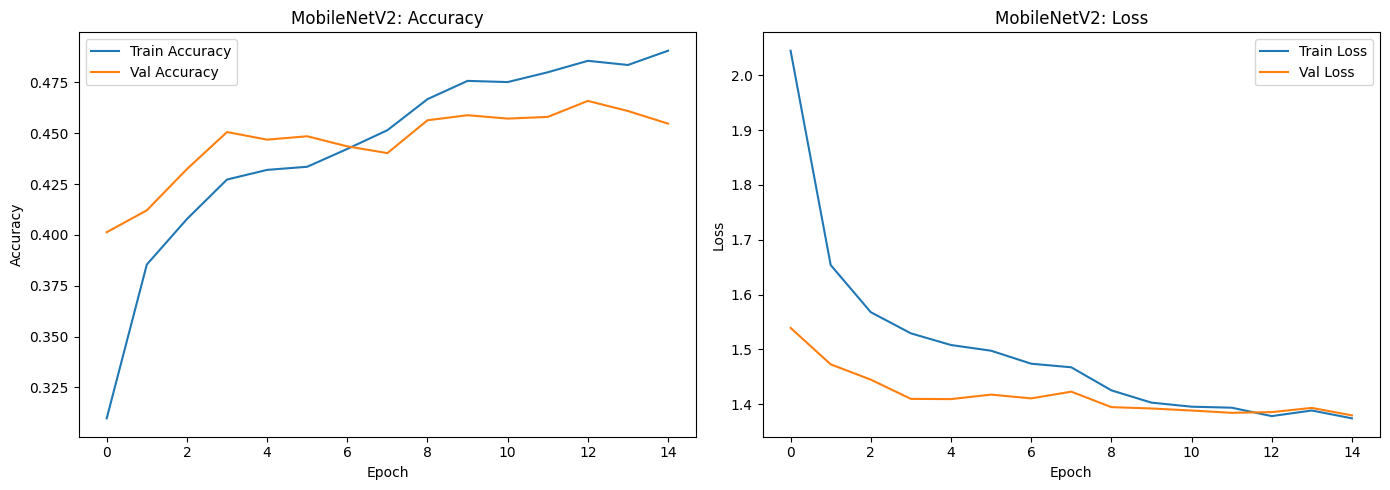

In [26]:
plot_history(mobilenet_history, "MobileNetV2")

The MobileNetV2 model is now being fully evaluated on the held-out Test set.


MobileNetV2 | Test Loss: 1.3952 | Test Accuracy: 0.4932

MobileNetV2 Classification Report:

              precision    recall  f1-score   support

       Anger      0.425     0.366     0.393      1718
    Contempt      0.362     0.536     0.432      1312
     Disgust      0.309     0.341     0.324      1248
        Fear      0.482     0.358     0.411      1664
       Happy      0.674     0.758     0.713      2704
     Neutral      0.584     0.677     0.627      2368
         Sad      0.440     0.381     0.409      1584
    Surprise      0.417     0.287     0.340      1920

    accuracy                          0.493     14518
   macro avg      0.462     0.463     0.456     14518
weighted avg      0.489     0.493     0.485     14518



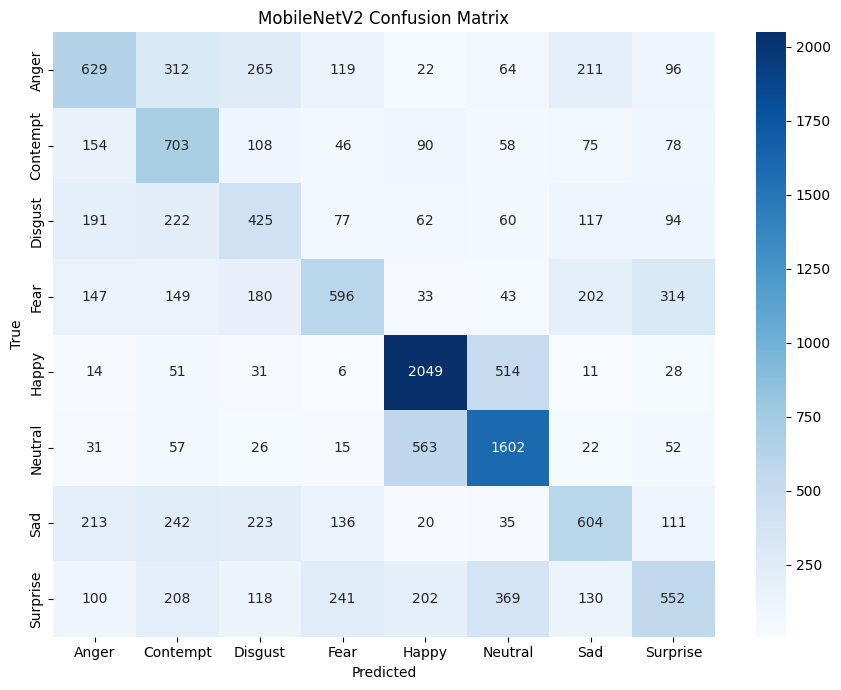

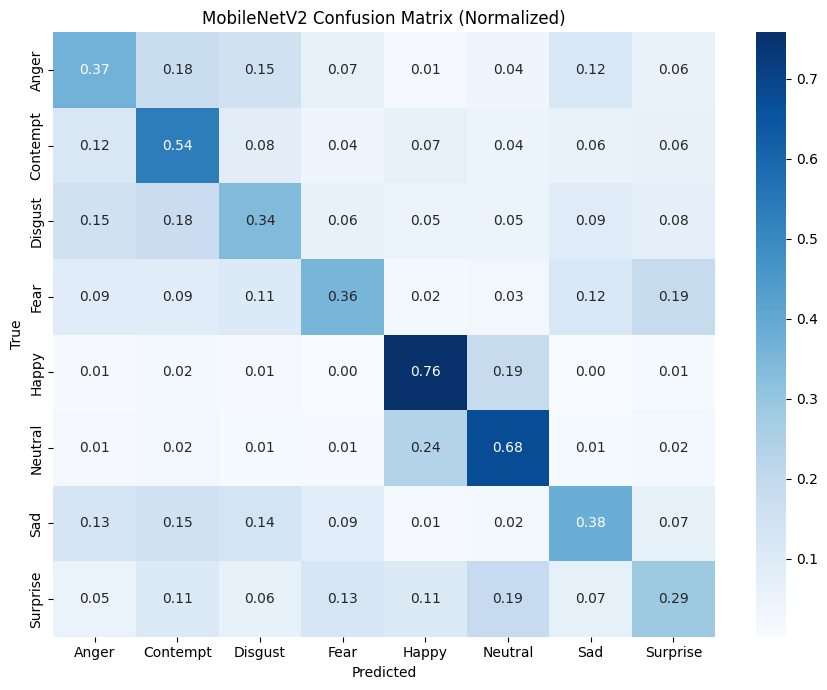

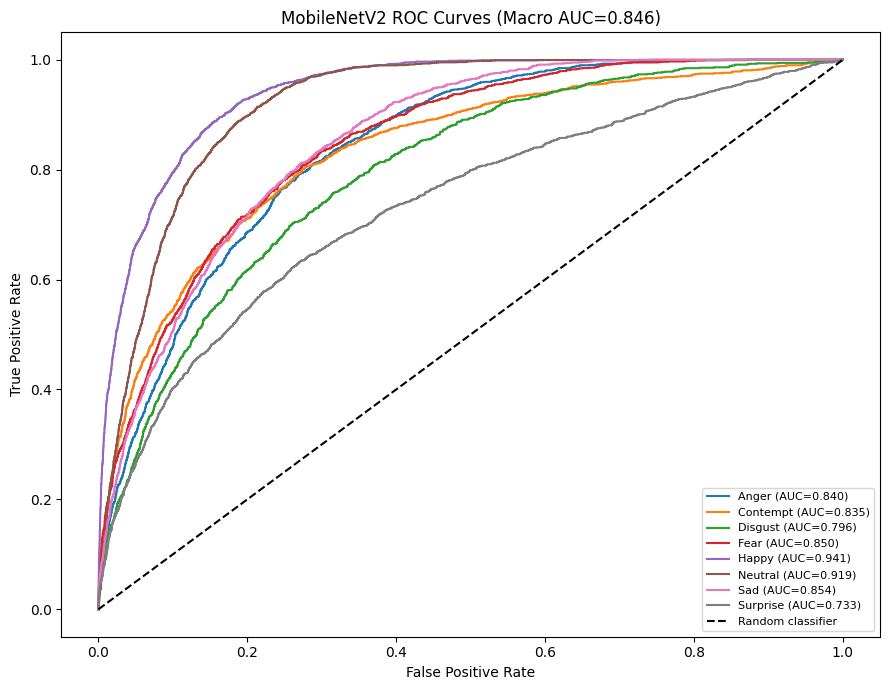


MobileNetV2 Per-class ROC-AUC:
  Anger     : 0.840
  Contempt  : 0.835
  Disgust   : 0.796
  Fear      : 0.850
  Happy     : 0.941
  Neutral   : 0.919
  Sad       : 0.854
  Surprise  : 0.733


In [27]:
mobilenet_y_true, mobilenet_y_pred, mobilenet_y_prob = evaluate_full(mobilenet_model, "MobileNetV2", test_ds, results)

# Section: DenseNet121
The second base model, DenseNet121, is now being trained and evaluated end-to-end.

## DenseNet121
The DenseNet121 model is now being built and trained with a frozen ImageNet backbone.

In [28]:
densenet_model, densenet_backbone = build_model("DenseNet121")
densenet_model.compile(optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy", metrics=["accuracy"])
densenet_model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "DenseNet121"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_net121_preprocess         │ (None, 224, 224, 3)    │             0 │
│ (DenseNet121Preprocess)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,307,080 (27.87 MB)

 Trainable params: 267,016 (1.02 MB)

 Non-trainable params: 7,040,064 (26.86 MB)

The DenseNet121 model is now being trained.

In [29]:
densenet_callbacks = get_callbacks("/content/densenet_best.keras", patience=5)
densenet_history = densenet_model.fit(train_ds, validation_data=val_ds, epochs=15,
    class_weight=class_weights, callbacks=densenet_callbacks)

Epoch 1/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 83s 159ms/step - accuracy: 0.3483 - loss: 1.8847 - val_accuracy: 0.4224 - val_loss: 1.4355 - learning_rate: 0.0010
Epoch 2/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 63s 146ms/step - accuracy: 0.4093 - loss: 1.5216 - val_accuracy: 0.4845 - val_loss: 1.3190 - learning_rate: 0.0010
Epoch 3/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 65s 151ms/step - accuracy: 0.4415 - loss: 1.4371 - val_accuracy: 0.4688 - val_loss: 1.3087 - learning_rate: 0.0010
Epoch 4/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 64s 149ms/step - accuracy: 0.4594 - loss: 1.3990 - val_accuracy: 0.4770 - val_loss: 1.3060 - learning_rate: 0.0010
Epoch 5/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 61s 142ms/step - accuracy: 0.4621 - loss: 1.3831 - val_accuracy: 0.4663 - val_loss: 1.3073 - learning_rate: 0.0010
Epoch 6/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 63s 148ms/step - accuracy: 0.4625 - loss: 1.3672 - val_accuracy: 0.4820 - val_loss: 1.3009 - learning_rate: 0.0010
Epoch 7/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 63s 148ms/step - accuracy: 0.4

Training and validation accuracy/loss curves for DenseNet121 are now being plotted.

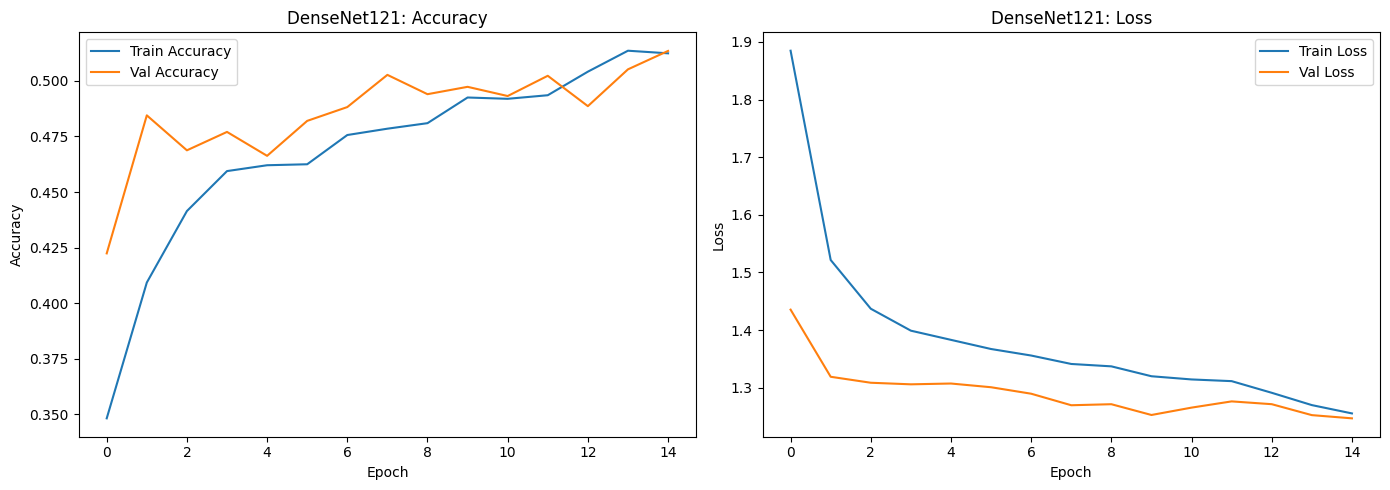

In [30]:
plot_history(densenet_history, "DenseNet121")

The DenseNet121 model is now being fully evaluated on the held-out Test set.


DenseNet121 | Test Loss: 1.4617 | Test Accuracy: 0.5204

DenseNet121 Classification Report:

              precision    recall  f1-score   support

       Anger      0.505     0.295     0.372      1718
    Contempt      0.355     0.643     0.458      1312
     Disgust      0.314     0.391     0.348      1248
        Fear      0.540     0.334     0.413      1664
       Happy      0.732     0.811     0.770      2704
     Neutral      0.649     0.744     0.694      2368
         Sad      0.434     0.439     0.436      1584
    Surprise      0.410     0.266     0.322      1920

    accuracy                          0.520     14518
   macro avg      0.492     0.490     0.477     14518
weighted avg      0.525     0.520     0.509     14518



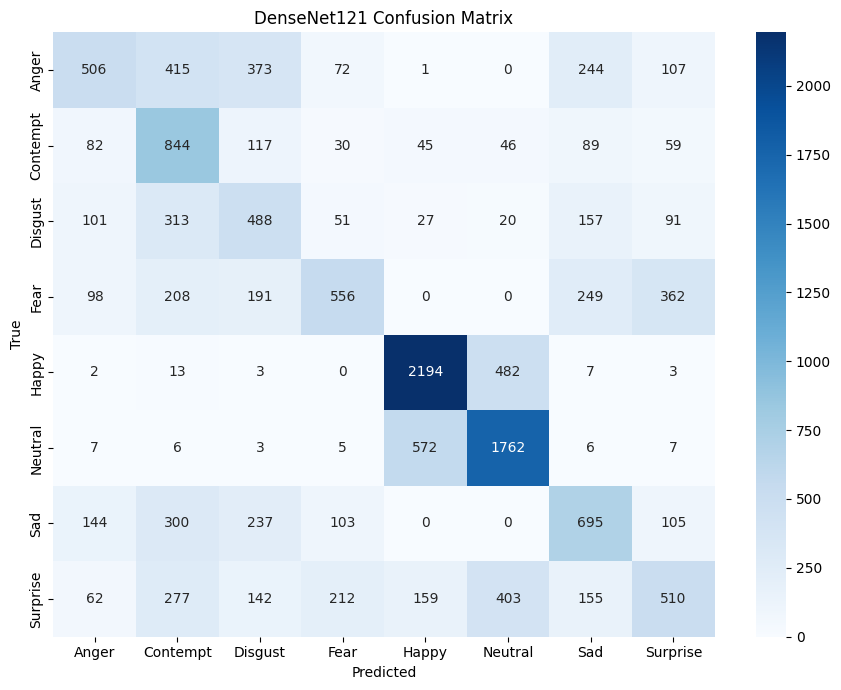

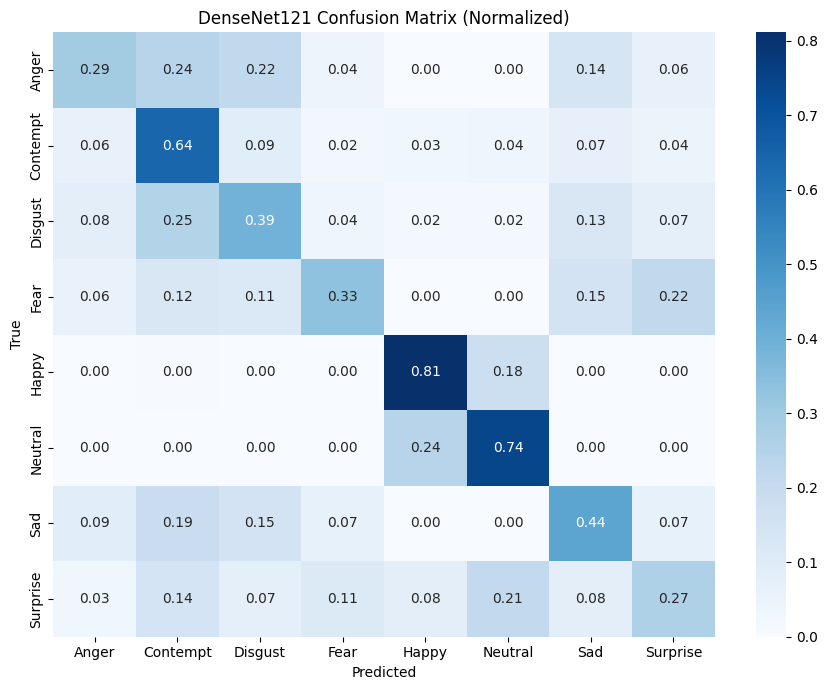

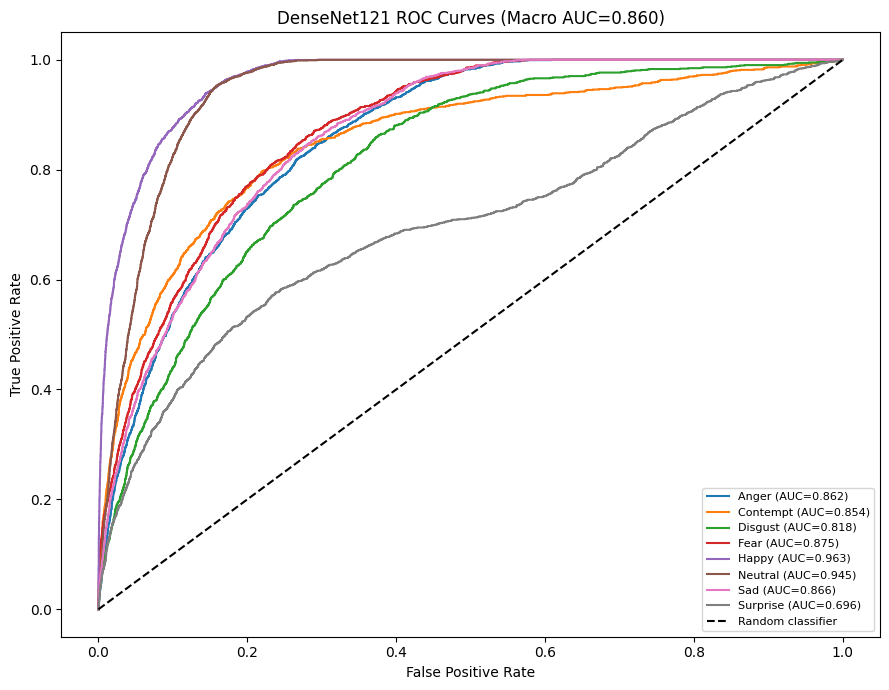


DenseNet121 Per-class ROC-AUC:
  Anger     : 0.862
  Contempt  : 0.854
  Disgust   : 0.818
  Fear      : 0.875
  Happy     : 0.963
  Neutral   : 0.945
  Sad       : 0.866
  Surprise  : 0.696


In [31]:
densenet_y_true, densenet_y_pred, densenet_y_prob = evaluate_full(densenet_model, "DenseNet121", test_ds, results)

# Section: ResNet50
The third base model, ResNet50, is now being trained and evaluated end-to-end.

## ResNet50
The ResNet50 model is now being built and trained with a frozen ImageNet backbone.

In [32]:
resnet_model, resnet_backbone = build_model("ResNet50")
resnet_model.compile(optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy", metrics=["accuracy"])
resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ res_net50_preprocess            │ (None, 224, 224, 3)    │             0 │
│ (ResNet50Preprocess)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,123,528 (92.02 MB)

 Trainable params: 531,208 (2.03 MB)

 Non-trainable params: 23,592,320 (90.00 MB)

The ResNet50 model is now being trained.

In [33]:
resnet_callbacks = get_callbacks("/content/resnet_best.keras", patience=5)
resnet_history = resnet_model.fit(train_ds, validation_data=val_ds, epochs=15,
    class_weight=class_weights, callbacks=resnet_callbacks)

Epoch 1/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 64s 128ms/step - accuracy: 0.3718 - loss: 1.8641 - val_accuracy: 0.4588 - val_loss: 1.3837 - learning_rate: 0.0010
Epoch 2/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 52s 121ms/step - accuracy: 0.4494 - loss: 1.4662 - val_accuracy: 0.4986 - val_loss: 1.2886 - learning_rate: 0.0010
Epoch 3/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 49s 115ms/step - accuracy: 0.4736 - loss: 1.3946 - val_accuracy: 0.4692 - val_loss: 1.3147 - learning_rate: 0.0010
Epoch 4/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 50s 116ms/step - accuracy: 0.4881 - loss: 1.3356 - val_accuracy: 0.4857 - val_loss: 1.2722 - learning_rate: 0.0010
Epoch 5/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 50s 116ms/step - accuracy: 0.4970 - loss: 1.3129 - val_accuracy: 0.4890 - val_loss: 1.2677 - learning_rate: 0.0010
Epoch 6/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 52s 122ms/step - accuracy: 0.5076 - loss: 1.3056 - val_accuracy: 0.4948 - val_loss: 1.2867 - learning_rate: 0.0010
Epoch 7/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 49s 114ms/step - accuracy: 0.5

Training and validation accuracy/loss curves for ResNet50 are now being plotted.

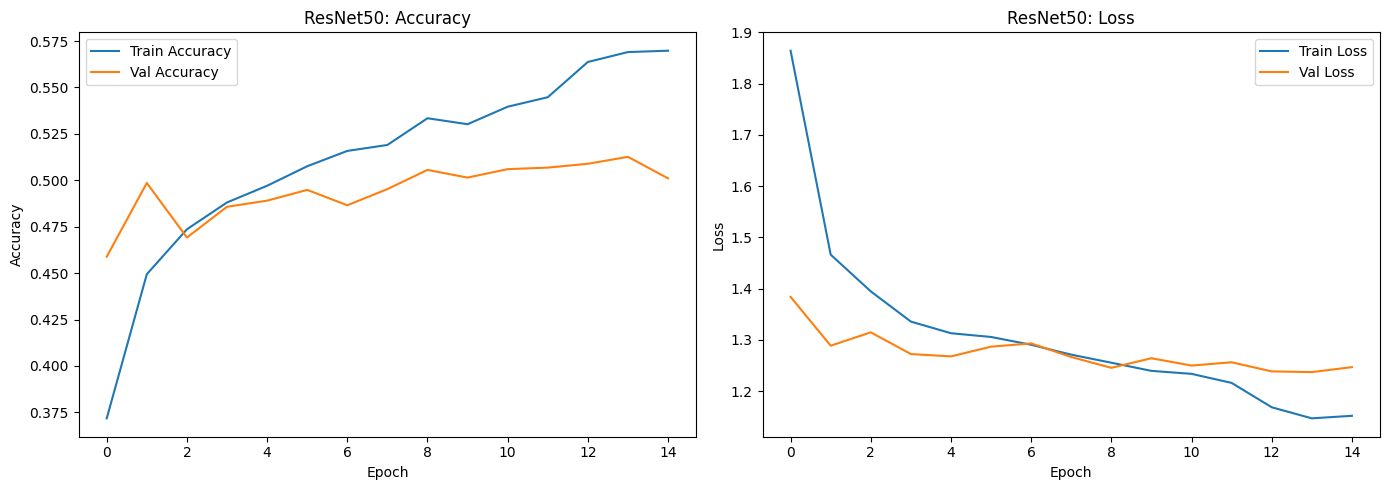

In [34]:
plot_history(resnet_history, "ResNet50")

The ResNet50 model is now being fully evaluated on the held-out Test set.


ResNet50 | Test Loss: 1.3857 | Test Accuracy: 0.5380

ResNet50 Classification Report:

              precision    recall  f1-score   support

       Anger      0.491     0.356     0.413      1718
    Contempt      0.399     0.570     0.470      1312
     Disgust      0.340     0.336     0.338      1248
        Fear      0.495     0.416     0.452      1664
       Happy      0.772     0.795     0.783      2704
     Neutral      0.644     0.790     0.709      2368
         Sad      0.503     0.423     0.460      1584
    Surprise      0.371     0.338     0.354      1920

    accuracy                          0.538     14518
   macro avg      0.502     0.503     0.497     14518
weighted avg      0.533     0.538     0.531     14518



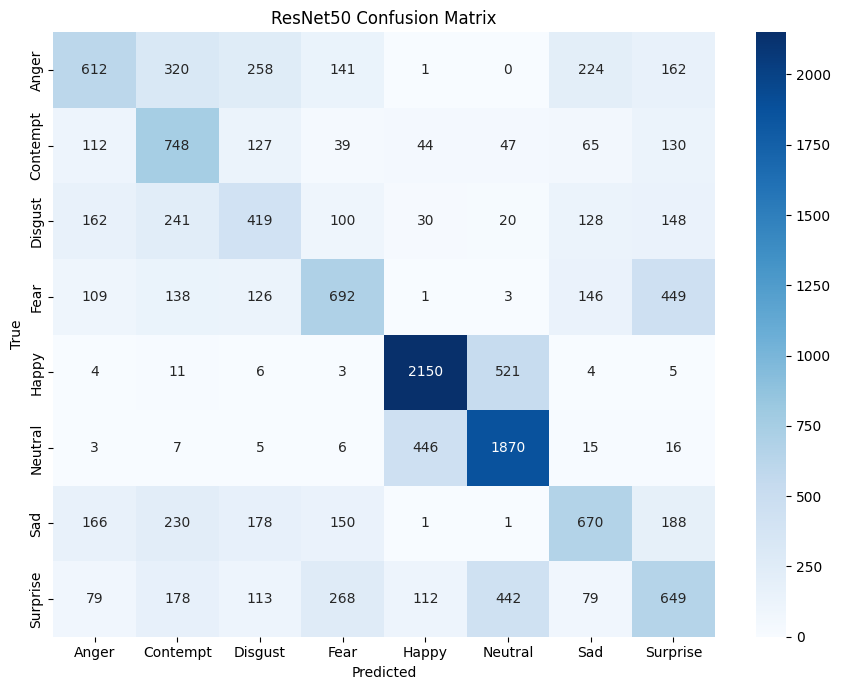

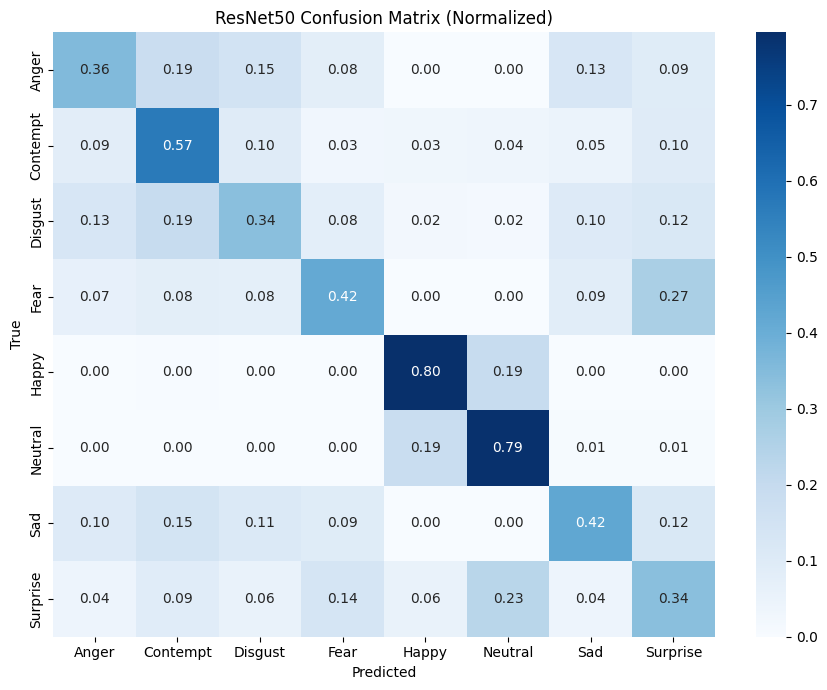

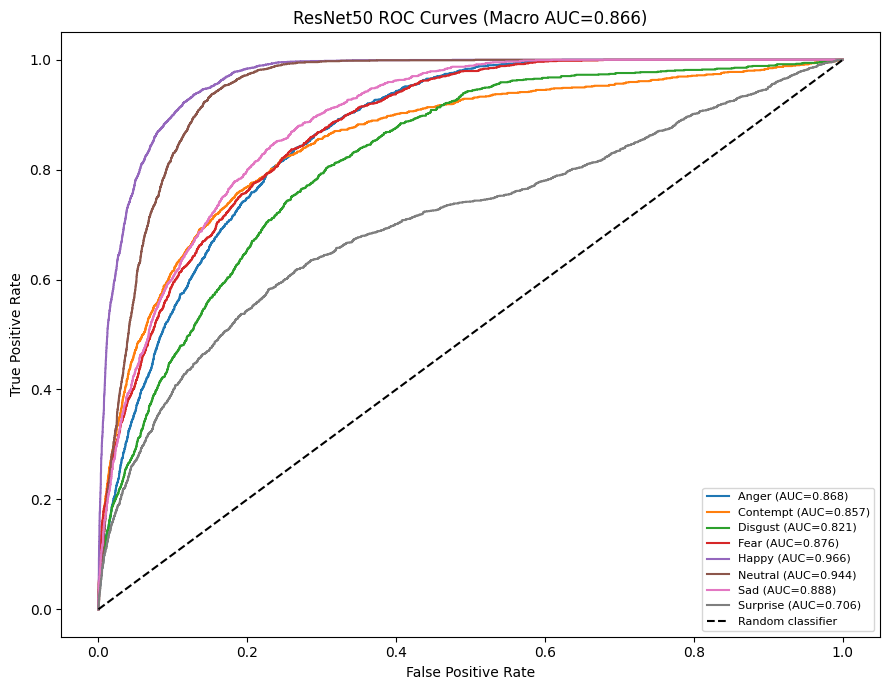


ResNet50 Per-class ROC-AUC:
  Anger     : 0.868
  Contempt  : 0.857
  Disgust   : 0.821
  Fear      : 0.876
  Happy     : 0.966
  Neutral   : 0.944
  Sad       : 0.888
  Surprise  : 0.706


In [35]:
resnet_y_true, resnet_y_pred, resnet_y_prob = evaluate_full(resnet_model, "ResNet50", test_ds, results)

# Model Comparison
All three frozen-backbone models are now being compared side by side.

In [36]:
comparison_df = pd.DataFrame(results).T[["Test Accuracy", "Macro Precision", "Macro Recall",
    "Macro F1", "Weighted F1", "Macro ROC-AUC"]].astype(float)
comparison_df = comparison_df.sort_values("Macro F1", ascending=False)
comparison_df

,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Macro ROC-AUC
ResNet50,0.537953,0.501960,0.502971,0.497340,0.530718,0.865735
DenseNet121,0.520388,0.492457,0.490356,0.476598,0.509353,0.859831
MobileNetV2,0.493181,0.461527,0.462971,0.456139,0.485192,0.846072


A grouped bar chart is now being plotted to visually compare the key metrics.

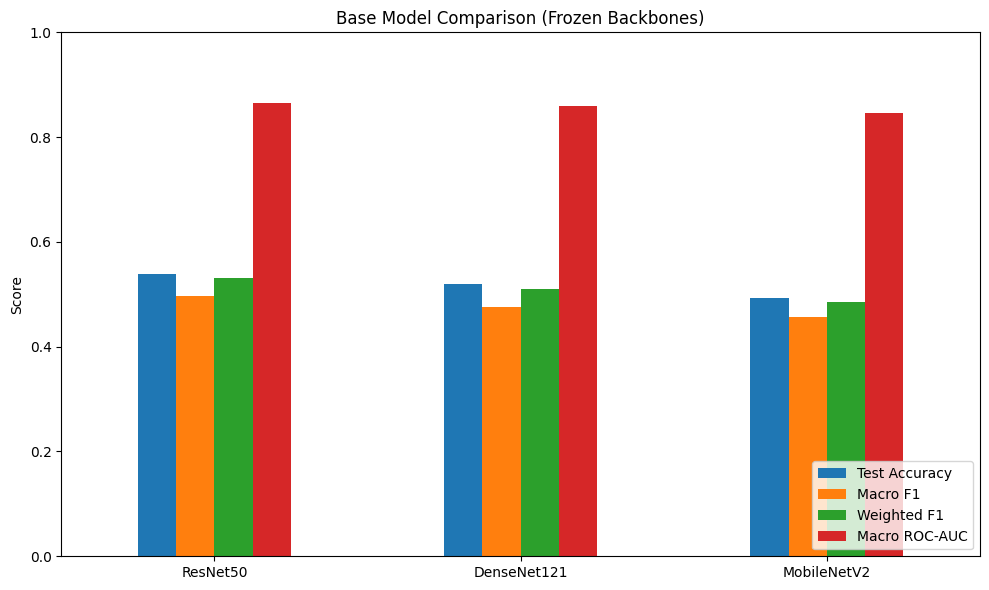

In [37]:
metrics_to_plot = ["Test Accuracy", "Macro F1", "Weighted F1", "Macro ROC-AUC"]
comparison_df[metrics_to_plot].plot(kind="bar", figsize=(10, 6))
plt.title("Base Model Comparison (Frozen Backbones)"); plt.ylabel("Score")
plt.xticks(rotation=0); plt.ylim(0, 1); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

# Best Model Selection
The best base model is now being selected automatically. **Macro F1** is used as the primary criterion since it treats every emotion class equally regardless of class imbalance; **Test Accuracy** and **Macro ROC-AUC** are used as secondary tie-breakers.

In [38]:
best_model_name = comparison_df.sort_values(["Macro F1", "Test Accuracy", "Macro ROC-AUC"],
    ascending=False).index[0]

print(f"Best model selected: {best_model_name}")
print(f"Reason: Macro F1 = {comparison_df.loc[best_model_name, 'Macro F1']:.4f}, "
      f"Test Accuracy = {comparison_df.loc[best_model_name, 'Test Accuracy']:.4f}, "
      f"Macro ROC-AUC = {comparison_df.loc[best_model_name, 'Macro ROC-AUC']:.4f} "
      f"— the highest Macro F1 among the three base models.")

model_registry = {"MobileNetV2": (mobilenet_model, mobilenet_backbone),
                   "DenseNet121": (densenet_model, densenet_backbone),
                   "ResNet50": (resnet_model, resnet_backbone)}
best_model, best_backbone = model_registry[best_model_name]

# Save the frozen-backbone version to disk before fine-tuning so it can be
# restored later if fine-tuning does not actually improve performance.
BASE_MODEL_PATH = f"/content/{best_model_name}_base_best.keras"
best_model.save(BASE_MODEL_PATH)
print(f"Base version of {best_model_name} checkpointed at: {BASE_MODEL_PATH}")

Best model selected: ResNet50
Reason: Macro F1 = 0.4973, Test Accuracy = 0.5380, Macro ROC-AUC = 0.8657 — the highest Macro F1 among the three base models.
Base version of ResNet50 checkpointed at: /content/ResNet50_base_best.keras


# Fine-Tuning the Best Model
Only the automatically selected best model is fine-tuned. A sensible fraction of the later backbone layers is unfrozen while BatchNormalization layers stay frozen (to preserve stable ImageNet statistics), and training continues with a very small learning rate.

In [39]:
UNFREEZE_FRACTION = {"MobileNetV2": 0.28, "DenseNet121": 0.28, "ResNet50": 0.22}

def unfreeze_backbone(backbone, fraction):
    backbone.trainable = True
    n_layers = len(backbone.layers)
    freeze_until = int(n_layers * (1 - fraction))
    for i, layer in enumerate(backbone.layers):
        layer.trainable = not (i < freeze_until or isinstance(layer, layers.BatchNormalization))
    trainable_count = sum(l.trainable for l in backbone.layers)
    print(f"Unfroze last {fraction*100:.0f}% of {backbone.name}: {trainable_count}/{n_layers} layers trainable")

unfreeze_backbone(best_backbone, UNFREEZE_FRACTION[best_model_name])
best_model.compile(optimizer=keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy", metrics=["accuracy"])

Unfroze last 22% of resnet50: 27/175 layers trainable


Fine-tuning training now begins for the selected best model.

In [40]:
ft_callbacks = get_callbacks(f"/content/{best_model_name}_finetuned_best.keras", patience=4)
finetune_history = best_model.fit(train_ds, validation_data=val_ds, epochs=10,
    class_weight=class_weights, callbacks=ft_callbacks)

Epoch 1/10
428/428 ━━━━━━━━━━━━━━━━━━━━ 78s 152ms/step - accuracy: 0.5935 - loss: 1.0873 - val_accuracy: 0.5379 - val_loss: 1.1567 - learning_rate: 1.0000e-05
Epoch 2/10
428/428 ━━━━━━━━━━━━━━━━━━━━ 76s 142ms/step - accuracy: 0.6228 - loss: 1.0101 - val_accuracy: 0.5523 - val_loss: 1.1415 - learning_rate: 1.0000e-05
Epoch 3/10
428/428 ━━━━━━━━━━━━━━━━━━━━ 60s 139ms/step - accuracy: 0.6379 - loss: 0.9795 - val_accuracy: 0.5494 - val_loss: 1.1174 - learning_rate: 1.0000e-05
Epoch 4/10
428/428 ━━━━━━━━━━━━━━━━━━━━ 60s 140ms/step - accuracy: 0.6557 - loss: 0.9324 - val_accuracy: 0.5676 - val_loss: 1.0983 - learning_rate: 1.0000e-05
Epoch 5/10
428/428 ━━━━━━━━━━━━━━━━━━━━ 66s 154ms/step - accuracy: 0.6688 - loss: 0.8992 - val_accuracy: 0.5809 - val_loss: 1.0819 - learning_rate: 1.0000e-05
Epoch 6/10
428/428 ━━━━━━━━━━━━━━━━━━━━ 61s 142ms/step - accuracy: 0.6894 - loss: 0.8640 - val_accuracy: 0.5854 - val_loss: 1.0689 - learning_rate: 1.0000e-05
Epoch 7/10
428/428 ━━━━━━━━━━━━━━━━━━━━ 63s 14

Fine-tuning accuracy and loss curves are now being plotted.

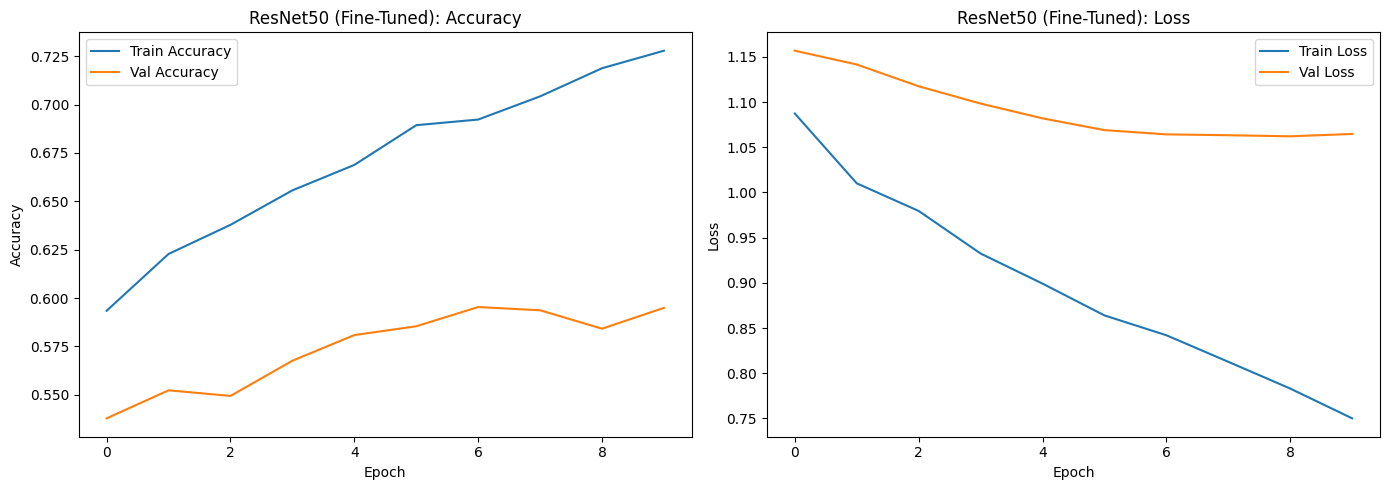

In [41]:
plot_history(finetune_history, f"{best_model_name} (Fine-Tuned)")

The fine-tuned model is now being fully evaluated on the Test set, repeating the same complete evaluation used for the base models.


ResNet50_FineTuned | Test Loss: 1.2586 | Test Accuracy: 0.6207

ResNet50_FineTuned Classification Report:

              precision    recall  f1-score   support

       Anger      0.582     0.430     0.495      1718
    Contempt      0.572     0.595     0.583      1312
     Disgust      0.403     0.514     0.452      1248
        Fear      0.596     0.419     0.492      1664
       Happy      0.808     0.923     0.861      2704
     Neutral      0.732     0.830     0.778      2368
         Sad      0.582     0.569     0.575      1584
    Surprise      0.441     0.412     0.426      1920

    accuracy                          0.621     14518
   macro avg      0.589     0.587     0.583     14518
weighted avg      0.615     0.621     0.613     14518



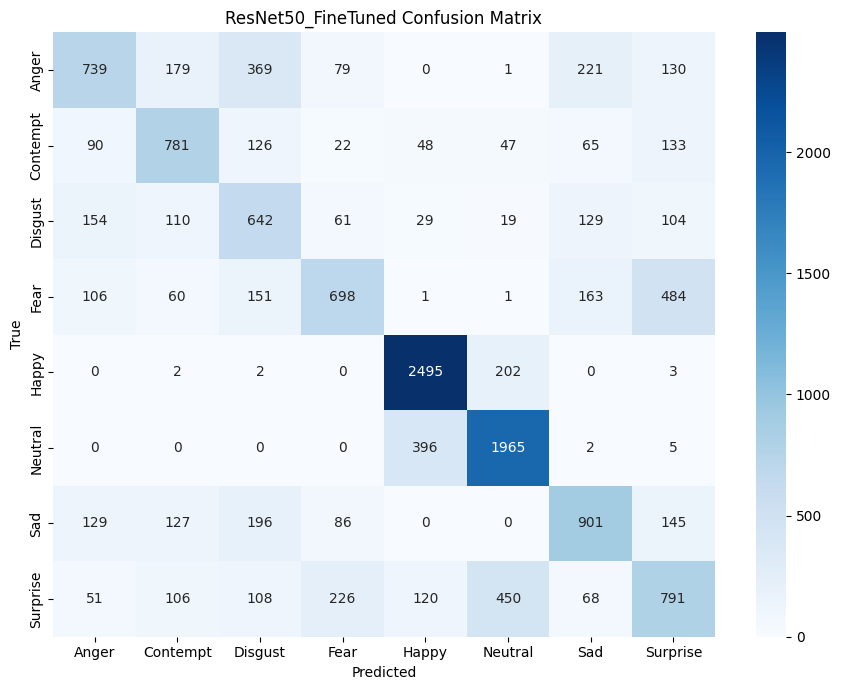

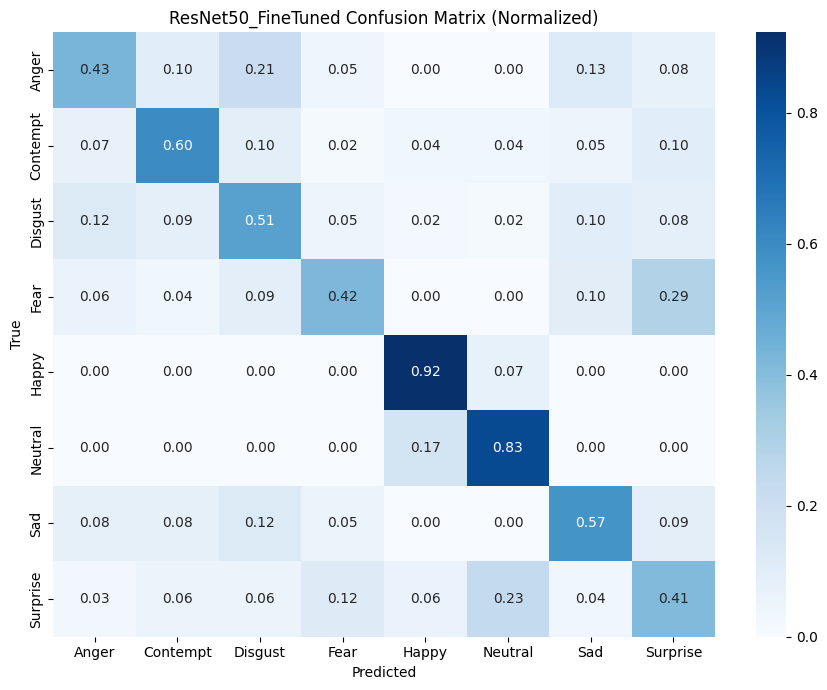

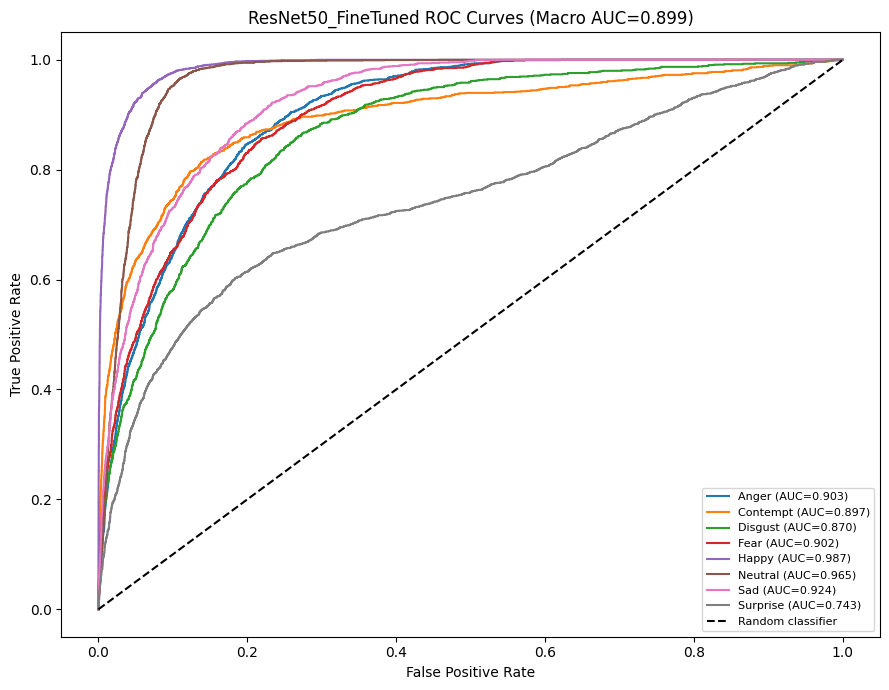


ResNet50_FineTuned Per-class ROC-AUC:
  Anger     : 0.903
  Contempt  : 0.897
  Disgust   : 0.870
  Fear      : 0.902
  Happy     : 0.987
  Neutral   : 0.965
  Sad       : 0.924
  Surprise  : 0.743


In [42]:
ft_key = f"{best_model_name}_FineTuned"
ft_y_true, ft_y_pred, ft_y_prob = evaluate_full(best_model, ft_key, test_ds, results)

# Base vs Fine-Tuned Comparison
The base best model is now being compared against its fine-tuned version.

In [43]:
ft_compare = pd.DataFrame({
    "Base Model": results[best_model_name],
    "Fine-Tuned Model": results[ft_key],
}).T[["Test Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "Weighted F1", "Macro ROC-AUC"]].astype(float)
ft_compare

,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Macro ROC-AUC
Base Model,0.537953,0.501960,0.502971,0.497340,0.530718,0.865735
Fine-Tuned Model,0.620747,0.589339,0.586579,0.582811,0.612904,0.898822


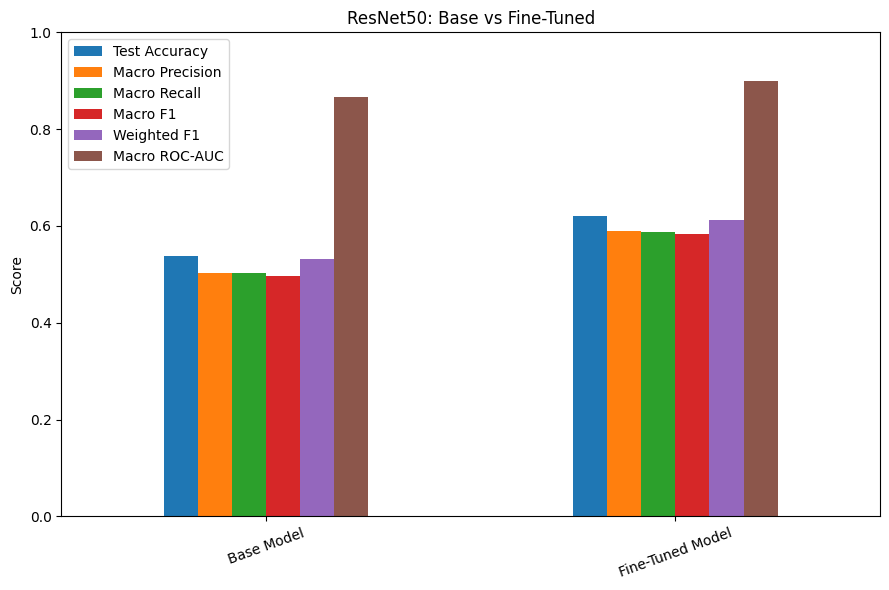

In [44]:
ft_compare.plot(kind="bar", figsize=(9, 6))
plt.title(f"{best_model_name}: Base vs Fine-Tuned"); plt.ylabel("Score")
plt.xticks(rotation=20); plt.ylim(0, 1); plt.tight_layout(); plt.show()

# Final Model Selection
Fine-tuning is not assumed to automatically improve results — the final model is chosen based on actual Macro F1 comparison. If fine-tuning underperforms, the checkpointed frozen-backbone version saved earlier is restored instead.

In [45]:
if ft_compare.loc["Fine-Tuned Model", "Macro F1"] >= ft_compare.loc["Base Model", "Macro F1"]:
    final_model = best_model
    final_model_source = f"{best_model_name} (Fine-Tuned)"
else:
    final_model = keras.models.load_model(BASE_MODEL_PATH)
    final_model_source = f"{best_model_name} (Base, frozen backbone)"

print(f"Final model selected: {final_model_source}")
print(f"Base Macro F1: {ft_compare.loc['Base Model', 'Macro F1']:.4f} | "
      f"Fine-Tuned Macro F1: {ft_compare.loc['Fine-Tuned Model', 'Macro F1']:.4f}")

Final model selected: ResNet50 (Fine-Tuned)
Base Macro F1: 0.4973 | Fine-Tuned Macro F1: 0.5828


# Random Test Predictions
Random images from the Test set are now being classified by the final model. Since preprocessing is embedded inside the model itself, the raw RGB image is passed directly, with no manual `preprocess_input` call.

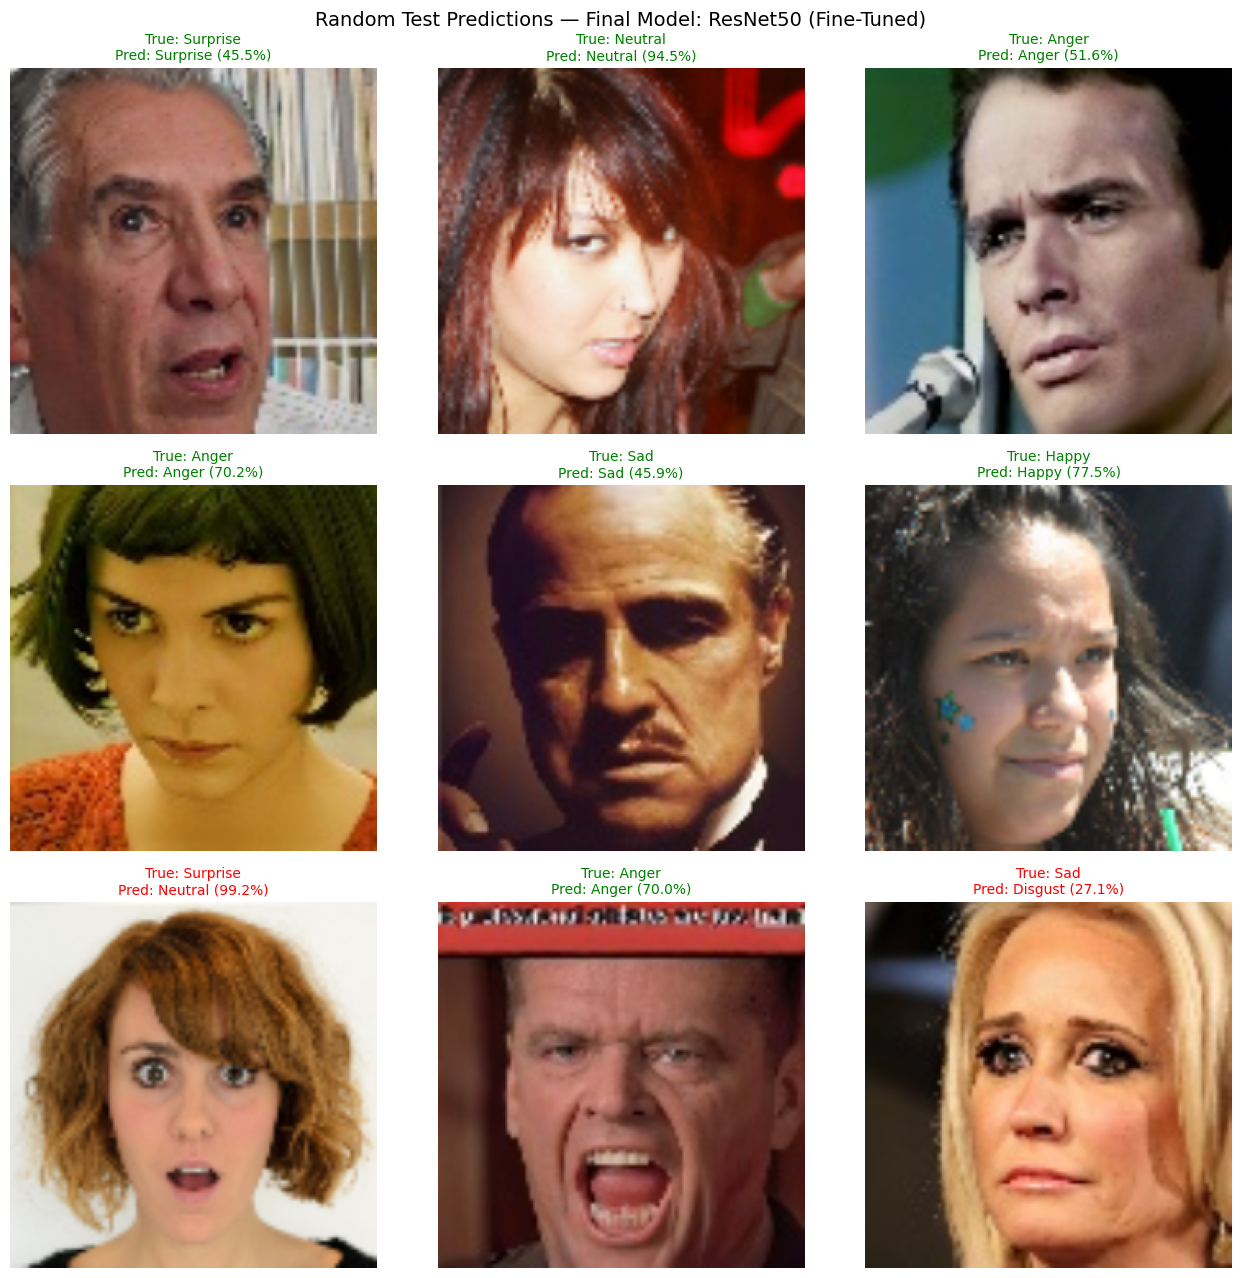

In [46]:
sample_indices = random.sample(range(len(test_df)), 9)
fig, axes = plt.subplots(3, 3, figsize=(13, 13))
for ax, idx in zip(axes.flatten(), sample_indices):
    row = test_df.iloc[idx]
    img = cv2.cvtColor(cv2.imread(row["filepath"]), cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img, IMG_SIZE).astype("float32")
    pred_prob = final_model.predict(np.expand_dims(img_resized, axis=0), verbose=0)[0]
    pred_idx = np.argmax(pred_prob)
    confidence = pred_prob[pred_idx] * 100
    true_label, pred_label = row["class_name"], CLASS_NAMES[pred_idx]
    correct = true_label == pred_label
    ax.imshow(img_resized.astype("uint8")); ax.axis("off")
    ax.set_title(f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)",
                 color="green" if correct else "red", fontsize=10)
plt.suptitle(f"Random Test Predictions — Final Model: {final_model_source}", fontsize=14)
plt.tight_layout(); plt.show()

# Save Final Model
The final selected model is now being saved to Google Drive as a native `.keras` file. Because preprocessing and augmentation are embedded inside the model graph, this file can be loaded later for real-time webcam inference without manually calling MobileNetV2/DenseNet/ResNet `preprocess_input` outside the model — only the raw RGB face crop is needed.

In [47]:
FINAL_MODEL_PATH = "/content/drive/MyDrive/Real_TIme_Emotion_Detection/best_emotion_model.keras"
os.makedirs(os.path.dirname(FINAL_MODEL_PATH), exist_ok=True)
final_model.save(FINAL_MODEL_PATH)

print("Final model saved to:", FINAL_MODEL_PATH)
print("File exists:", os.path.exists(FINAL_MODEL_PATH))

Final model saved to: /content/drive/MyDrive/Real_TIme_Emotion_Detection/best_emotion_model.keras
File exists: True


**Loading this model later (e.g. in `webcam_detection.py`)** requires the custom preprocessing layer classes (`MobileNetV2Preprocess`, `DenseNet121Preprocess`, `ResNet50Preprocess`) to be defined and registered with `@tf.keras.utils.register_keras_serializable(package="EmotionCNN")` in that script before calling `keras.models.load_model()` — or passed explicitly via the `custom_objects` argument. Since only one of the three is actually used inside the saved model, only that one class needs to be redefined.

Comparison results are now being saved to Google Drive as CSV files for reference.

In [48]:
RESULTS_DIR = "/content/drive/MyDrive/Real_TIme_Emotion_Detection"
comparison_df.to_csv(os.path.join(RESULTS_DIR, "base_model_comparison.csv"))
ft_compare.to_csv(os.path.join(RESULTS_DIR, "finetuning_comparison.csv"))
print("Comparison CSVs saved to:", RESULTS_DIR)

Comparison CSVs saved to: /content/drive/MyDrive/Real_TIme_Emotion_Detection


# Final Summary

In [49]:
print("=" * 60)
print("PROJECT SUMMARY")
print("=" * 60)
print(f"Best base model (frozen backbone): {best_model_name}")
print(f"Final selected model:              {final_model_source}")
print(f"Final Test Accuracy:  {results[ft_key if final_model_source.endswith('(Fine-Tuned)') else best_model_name]['Test Accuracy']:.4f}")
print(f"Final Macro F1:       {results[ft_key if final_model_source.endswith('(Fine-Tuned)') else best_model_name]['Macro F1']:.4f}")
print(f"Final Macro ROC-AUC:  {results[ft_key if final_model_source.endswith('(Fine-Tuned)') else best_model_name]['Macro ROC-AUC']:.4f}")
print(f"Model saved at: {FINAL_MODEL_PATH}")
print("=" * 60)

PROJECT SUMMARY
Best base model (frozen backbone): ResNet50
Final selected model:              ResNet50 (Fine-Tuned)
Final Test Accuracy:  0.6207
Final Macro F1:       0.5828
Final Macro ROC-AUC:  0.8988
Model saved at: /content/drive/MyDrive/Real_TIme_Emotion_Detection/best_emotion_model.keras
